m = 1.0
R = 1.0
k = 1.0
I3 = 0.5
J = 0.25
M = 1.5

Case 1
Initial condition = [2.0, 0.0, 0.8, 1.5707963267948966, 0.2]
Final time = 100.0
Number of time points = 10000
Simulation completed normally.

Case 2
Initial condition = [2.0, 0.0, 0.8, 1.5707963267948966, 0.4]
Final time = 100.0
Number of time points = 10000
Simulation completed normally.

Case 3
Initial condition = [2.0, 0.0, 1.0, 1.5707963267948966, 0.2]
Final time = 100.0
Number of time points = 10000
Simulation completed normally.

Case 4
Initial condition = [2.0, 0.0, 0.8, 1.0471975511965976, 0.2]
Final time = 100.0
Number of time points = 10000
Simulation completed normally.


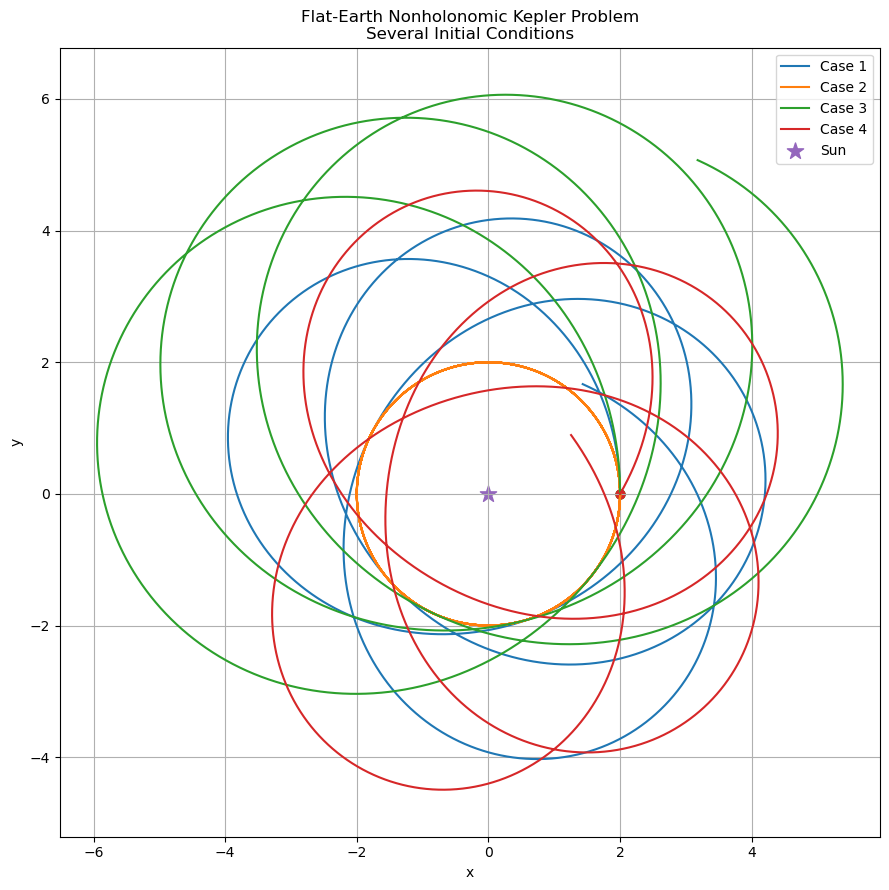

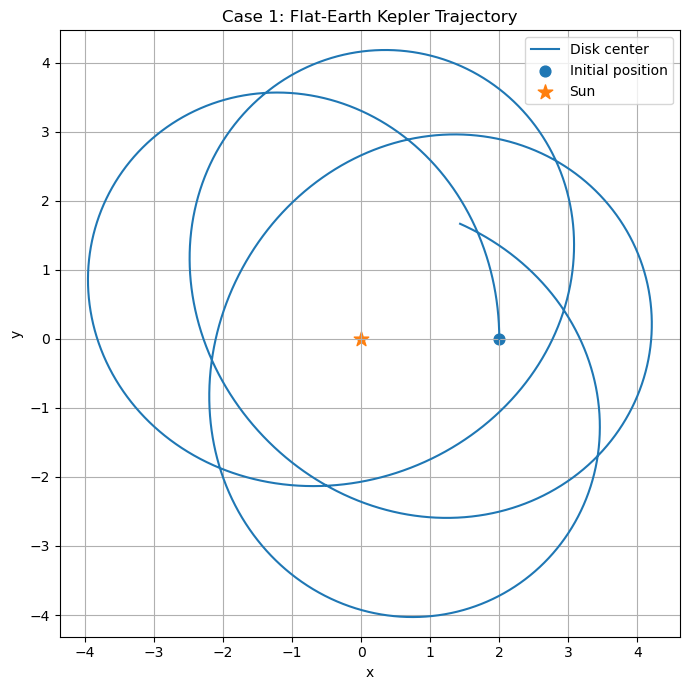

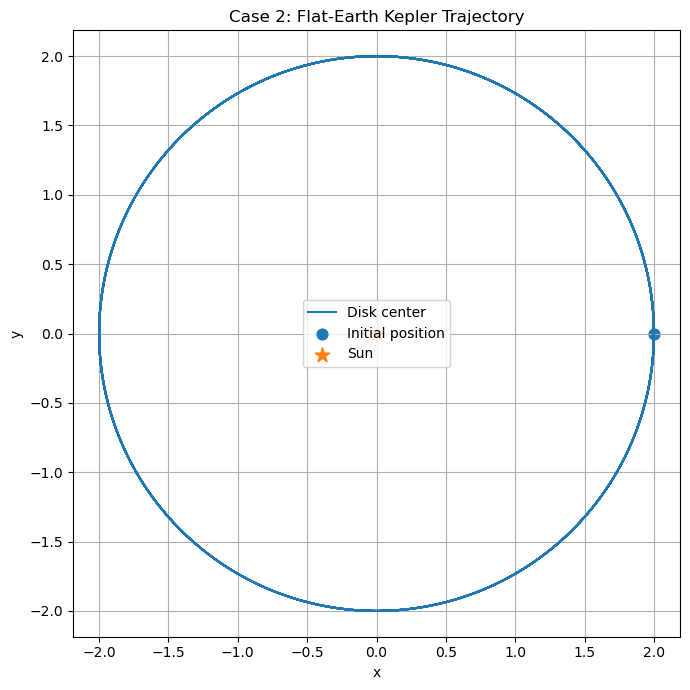

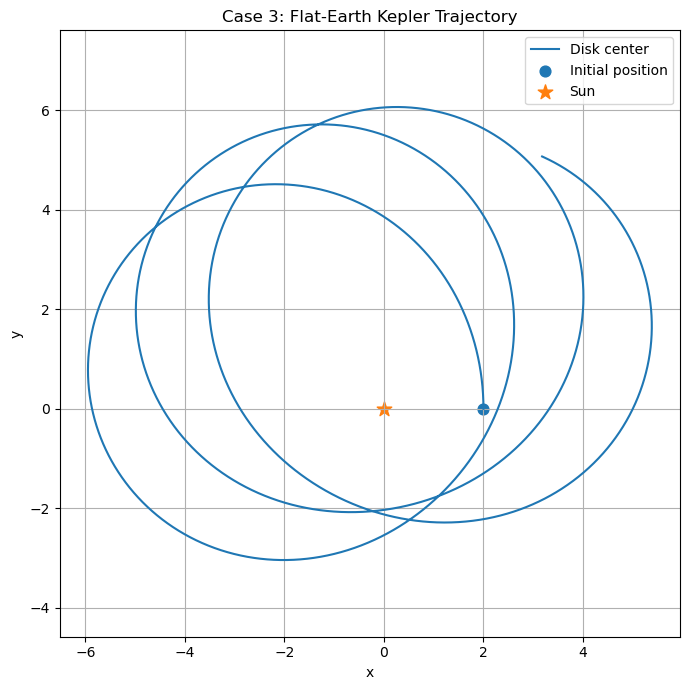

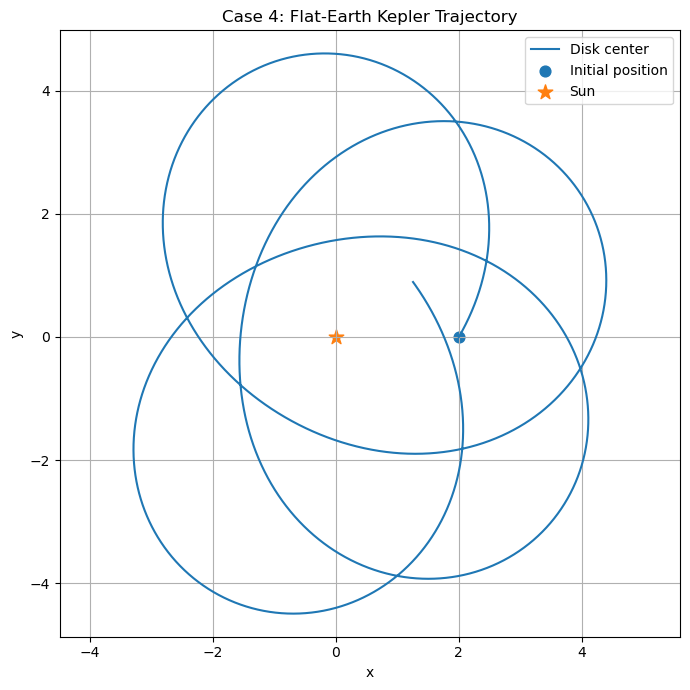

Saved: case_1_simulation.csv
Saved: case_2_simulation.csv
Saved: case_3_simulation.csv
Saved: case_4_simulation.csv


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp


# ============================================================
# Parameters
# ============================================================

m = 1.0
R = 1.0
k = 1.0

# Homogeneous thin disk
I3 = 0.5 * m * R**2
J = 0.25 * m * R**2

# Effective translational mass
M = m + I3 / R**2

print("m =", m)
print("R =", R)
print("k =", k)
print("I3 =", I3)
print("J =", J)
print("M =", M)


# ============================================================
# First-order equations
#
# State:
# y = [x, y, v, theta, omega]
# ============================================================

def flat_earth_kepler(t, state):

    x, y, v, theta, omega = state

    r = np.sqrt(x**2 + y**2)

    # Protect against the singularity at the Sun
    if r < 1e-8:
        r = 1e-8

    dxdt = v * np.cos(theta)

    dydt = v * np.sin(theta)

    q_dot_e = (
        x * np.cos(theta)
        +
        y * np.sin(theta)
    )

    dvdt = (
        -(k / M)
        * q_dot_e
        / r**3
    )

    dthetadt = omega

    domegadt = 0.0

    return [
        dxdt,
        dydt,
        dvdt,
        dthetadt,
        domegadt
    ]


# ============================================================
# Stop the simulation if the disk gets too close to the Sun
# ============================================================

def collision_event(t, state):

    x, y, v, theta, omega = state

    r = np.sqrt(x**2 + y**2)

    minimum_radius = 0.1

    return r - minimum_radius


collision_event.terminal = True
collision_event.direction = -1


# ============================================================
# Several initial conditions
#
# Format:
# [x0, y0, v0, theta0, omega0]
# ============================================================

initial_conditions = {

    "Case 1": [
        2.0,
        0.0,
        0.8,
        np.pi / 2,
        0.20
    ],

    "Case 2": [
        2.0,
        0.0,
        0.8,
        np.pi / 2,
        0.40
    ],

    "Case 3": [
        2.0,
        0.0,
        1.0,
        np.pi / 2,
        0.20
    ],

    "Case 4": [
        2.0,
        0.0,
        0.8,
        np.pi / 3,
        0.20
    ]
}


# ============================================================
# Time interval
# ============================================================

t_start = 0.0
t_end = 100.0

t_eval = np.linspace(
    t_start,
    t_end,
    10000
)


# ============================================================
# Solve all initial conditions
# ============================================================

solutions = {}

for name, initial_state in initial_conditions.items():

    solution = solve_ivp(
        flat_earth_kepler,
        (t_start, t_end),
        initial_state,
        t_eval=t_eval,
        rtol=1e-10,
        atol=1e-12,
        events=collision_event
    )

    solutions[name] = solution

    print()
    print(name)
    print("Initial condition =", initial_state)
    print("Final time =", solution.t[-1])
    print("Number of time points =", len(solution.t))

    if len(solution.t_events[0]) > 0:
        print("Stopped because disk approached the Sun.")
    else:
        print("Simulation completed normally.")


# ============================================================
# Plot all trajectories together
# ============================================================

plt.figure(figsize=(9, 9))

for name, solution in solutions.items():

    x = solution.y[0]
    y = solution.y[1]

    plt.plot(
        x,
        y,
        label=name
    )

    # Initial position
    plt.scatter(
        [x[0]],
        [y[0]],
        s=40
    )


# Sun
plt.scatter(
    [0],
    [0],
    s=150,
    marker="*",
    label="Sun"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Flat-Earth Nonholonomic Kepler Problem\n"
    "Several Initial Conditions"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "flat_earth_multiple_trajectories.png",
    dpi=300
)

plt.show()


# ============================================================
# Plot each trajectory separately
# ============================================================

for name, solution in solutions.items():

    x = solution.y[0]
    y = solution.y[1]

    plt.figure(figsize=(7, 7))

    plt.plot(
        x,
        y,
        label="Disk center"
    )

    plt.scatter(
        [x[0]],
        [y[0]],
        s=60,
        label="Initial position"
    )

    plt.scatter(
        [0],
        [0],
        s=120,
        marker="*",
        label="Sun"
    )

    plt.xlabel("x")
    plt.ylabel("y")

    plt.title(
        f"{name}: Flat-Earth Kepler Trajectory"
    )

    plt.axis("equal")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()

    filename = (
        name.lower()
        .replace(" ", "_")
        + "_trajectory.png"
    )

    plt.savefig(
        filename,
        dpi=300
    )

    plt.show()


# ============================================================
# Save numerical results
# ============================================================

for name, solution in solutions.items():

    df = pd.DataFrame({

        "time":
            solution.t,

        "x":
            solution.y[0],

        "y":
            solution.y[1],

        "v":
            solution.y[2],

        "theta":
            solution.y[3],

        "omega":
            solution.y[4]
    })

    filename = (
        name.lower()
        .replace(" ", "_")
        + "_simulation.csv"
    )

    df.to_csv(
        filename,
        index=False
    )

    print(
        "Saved:",
        filename
    )


Case 1
Initial energy = -0.014999999999999902
Minimum energy = -0.015000000211313425
Maximum energy = -0.014999999504287598
Maximum absolute energy error = 4.957123045379319e-10
Maximum relative energy error = 3.304748696919568e-08

Case 2
Initial energy = 1.1102230246251565e-16
Minimum energy = -2.7755575615628914e-15
Maximum energy = 4.2984393822109723e-11
Maximum absolute energy error = 4.298428279980726e-11
Maximum relative energy error = 42984.28279980726

Case 3
Initial energy = 0.255
Minimum energy = 0.25499999940468554
Maximum energy = 0.2550000009519002
Maximum absolute energy error = 9.519001697988472e-10
Maximum relative energy error = 3.7329418423484204e-09

Case 4
Initial energy = -0.014999999999999902
Minimum energy = -0.015000000431851124
Maximum energy = -0.01499999920985362
Maximum absolute energy error = 7.901462817372362e-10
Maximum relative energy error = 5.267641878248276e-08


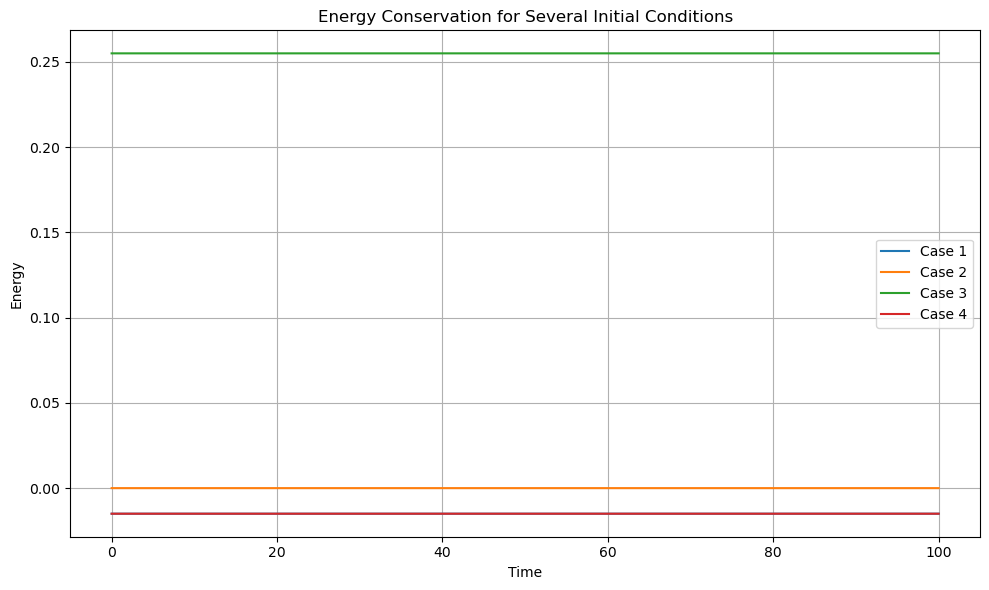

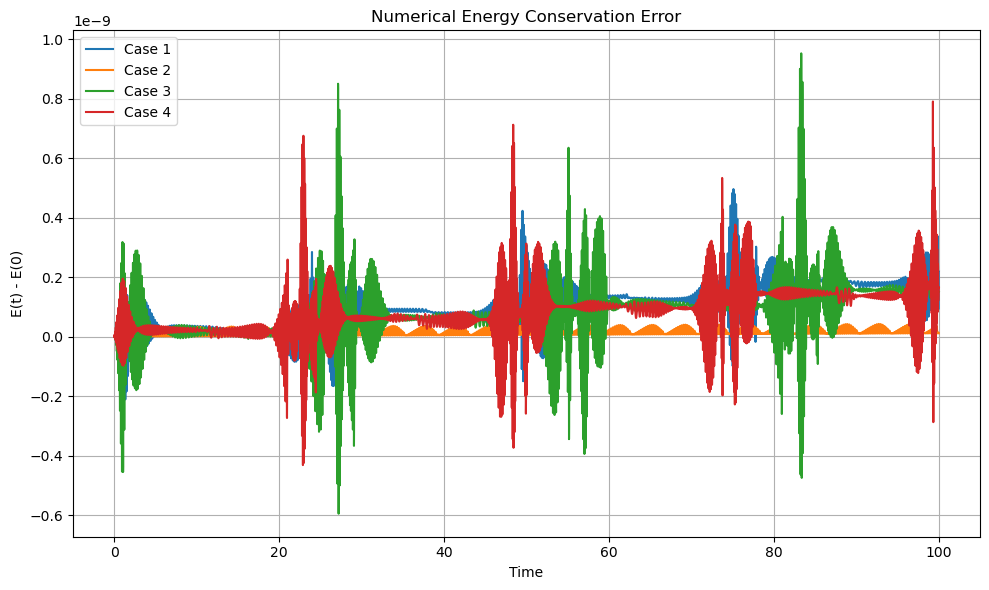


Energy conservation summary:

  Case  Initial_Energy  Minimum_Energy  Maximum_Energy  Max_Absolute_Error  Max_Relative_Error
Case 1   -1.500000e-02   -1.500000e-02   -1.500000e-02        4.957123e-10        3.304749e-08
Case 2    1.110223e-16   -2.775558e-15    4.298439e-11        4.298428e-11        4.298428e+04
Case 3    2.550000e-01    2.550000e-01    2.550000e-01        9.519002e-10        3.732942e-09
Case 4   -1.500000e-02   -1.500000e-02   -1.500000e-02        7.901463e-10        5.267642e-08

Saved energy_conservation_summary.csv


In [2]:
# ============================================================
# STEP 5: ENERGY CONSERVATION
# ============================================================

energy_results = []

plt.figure(figsize=(10, 6))

for name, solution in solutions.items():

    t = solution.t

    x = solution.y[0]
    y = solution.y[1]
    v = solution.y[2]
    theta = solution.y[3]
    omega = solution.y[4]

    # Distance from the Sun
    r = np.sqrt(x**2 + y**2)

    # Total mechanical energy
    E = (
        0.5 * M * v**2
        +
        0.5 * J * omega**2
        -
        k / r
    )

    E0 = E[0]

    # Absolute change from initial energy
    energy_error = E - E0

    # Maximum absolute drift
    max_abs_error = np.max(
        np.abs(energy_error)
    )

    # Maximum relative drift
    max_relative_error = (
        max_abs_error
        /
        max(abs(E0), 1e-15)
    )

    energy_results.append({
        "Case": name,
        "Initial_Energy": E0,
        "Minimum_Energy": np.min(E),
        "Maximum_Energy": np.max(E),
        "Max_Absolute_Error": max_abs_error,
        "Max_Relative_Error": max_relative_error
    })

    print()
    print(name)
    print("Initial energy =", E0)
    print("Minimum energy =", np.min(E))
    print("Maximum energy =", np.max(E))
    print("Maximum absolute energy error =", max_abs_error)
    print("Maximum relative energy error =", max_relative_error)

    # Plot energy itself
    plt.plot(
        t,
        E,
        label=name
    )


plt.xlabel("Time")
plt.ylabel("Energy")

plt.title(
    "Energy Conservation for Several Initial Conditions"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "energy_conservation_all_cases.png",
    dpi=300
)

plt.show()


# ============================================================
# Plot energy error E(t) - E(0)
# ============================================================

plt.figure(figsize=(10, 6))

for name, solution in solutions.items():

    t = solution.t

    x = solution.y[0]
    y = solution.y[1]
    v = solution.y[2]
    omega = solution.y[4]

    r = np.sqrt(x**2 + y**2)

    E = (
        0.5 * M * v**2
        +
        0.5 * J * omega**2
        -
        k / r
    )

    energy_error = E - E[0]

    plt.plot(
        t,
        energy_error,
        label=name
    )


plt.xlabel("Time")
plt.ylabel("E(t) - E(0)")

plt.title(
    "Numerical Energy Conservation Error"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "energy_error_all_cases.png",
    dpi=300
)

plt.show()


# ============================================================
# Save summary table
# ============================================================

energy_summary = pd.DataFrame(
    energy_results
)

print()
print("Energy conservation summary:")
print()

print(
    energy_summary.to_string(
        index=False
    )
)

energy_summary.to_csv(
    "energy_conservation_summary.csv",
    index=False
)

print()
print(
    "Saved energy_conservation_summary.csv"
)

# 5. Energy Conservation

The total mechanical energy is

$$
E
=
\frac{1}{2}Mv^2
+
\frac{1}{2}J\omega^2
-
\frac{k}{|q|}.
$$

Since

$$
|q|
=
\sqrt{x^2+y^2},
$$

the energy used in the numerical simulation was

$$
E
=
\frac{1}{2}Mv^2
+
\frac{1}{2}J\omega^2
-
\frac{k}{\sqrt{x^2+y^2}}.
$$

The energy was evaluated at every time step for each of the four initial conditions.

## Numerical Results

| Case | Initial Energy | Maximum Absolute Energy Error |
| --- | ---: | ---: |
| Case 1 | -0.015000 | 4.96e-10 |
| Case 2 | approximately 0 | 4.30e-11 |
| Case 3 | 0.255000 | 9.52e-10 |
| Case 4 | -0.015000 | 7.90e-10 |

![Energy conservation](energy_conservation_all_cases.png)

The energy curves appear constant throughout the simulation.

To examine the numerical error more closely, I also plotted

$$
E(t)-E(0).
$$

![Energy conservation error](energy_error_all_cases.png)

The energy errors remain approximately between $10^{-10}$ and $10^{-9}$ over the entire simulation. These variations are extremely small and are consistent with numerical integration and floating-point error.

## Special Case: Case 2

Case 2 appears to have an extremely large relative energy error if the error is divided by the initial energy. However, this is misleading because the initial energy is theoretically zero.

For Case 2,

$$
M=1.5,
$$

$$
v_0=0.8,
$$

$$
J=0.25,
$$

$$
\omega_0=0.4,
$$

and

$$
|q_0|=2.
$$

Therefore,

$$
E(0)
=
\frac{1}{2}(1.5)(0.8)^2
+
\frac{1}{2}(0.25)(0.4)^2
-
\frac{1}{2}.
$$

This gives

$$
E(0)
=
0.48+0.02-0.50
=
0.
$$

The value produced by Python,

$$
E(0)
\approx
1.11\times10^{-16},
$$

is simply floating-point roundoff.

Therefore, a relative error based on division by $E(0)$ is not meaningful for Case 2. The appropriate quantity to examine is the absolute energy drift, which is only about

$$
4.3\times10^{-11}.
$$

## Conclusion

The numerical experiment confirms that the total mechanical energy

$$
E
=
\frac{1}{2}Mv^2
+
\frac{1}{2}J\omega^2
-
\frac{k}{|q|}
$$

is conserved in this simplified nonholonomic model.

All four simulations show energy variation of approximately $10^{-9}$ or smaller, which is consistent with numerical error rather than physical energy loss or gain.


Case 1
Initial Lorb = 2.4000000000000004
Minimum Lorb = 2.3994788534258165
Maximum Lorb = 3.4063643544004005
Maximum absolute change = 1.0063643544004002
Maximum relative change = 0.41931848100016667

Case 2
Initial Lorb = 2.4000000000000004
Minimum Lorb = 2.3999999999994306
Maximum Lorb = 2.400000000148455
Maximum absolute change = 1.4845458196077743e-10
Maximum relative change = 6.185607581699058e-11

Case 3
Initial Lorb = 3.0
Minimum Lorb = 3.0
Maximum Lorb = 6.77782669185699
Maximum absolute change = 3.7778266918569896
Maximum relative change = 1.2592755639523299

Case 4
Initial Lorb = 2.078460969082653
Minimum Lorb = 2.075370872656973
Maximum Lorb = 3.545083754026116
Maximum absolute change = 1.4666227849434632
Maximum relative change = 0.7056292164056225


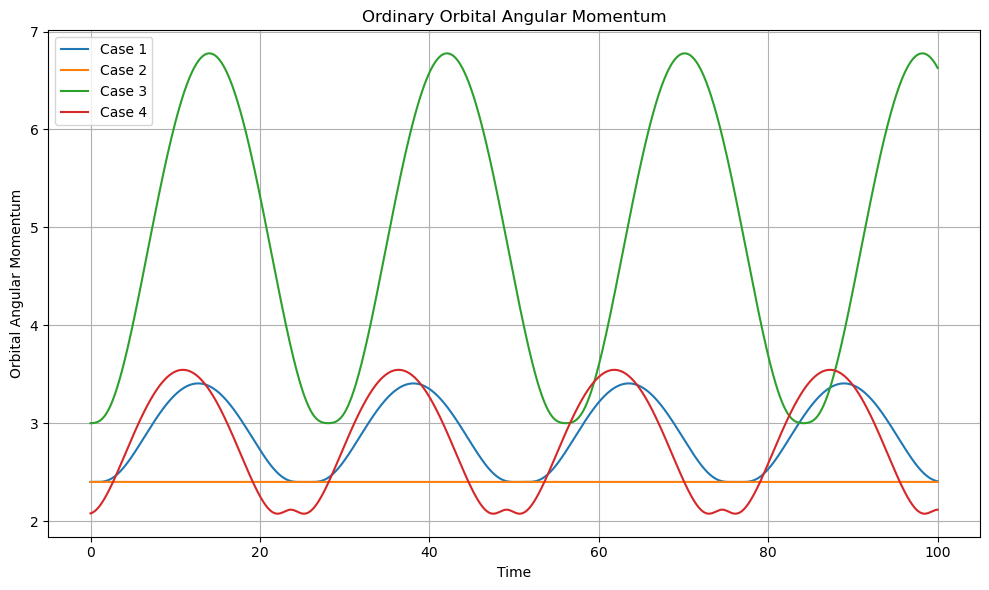

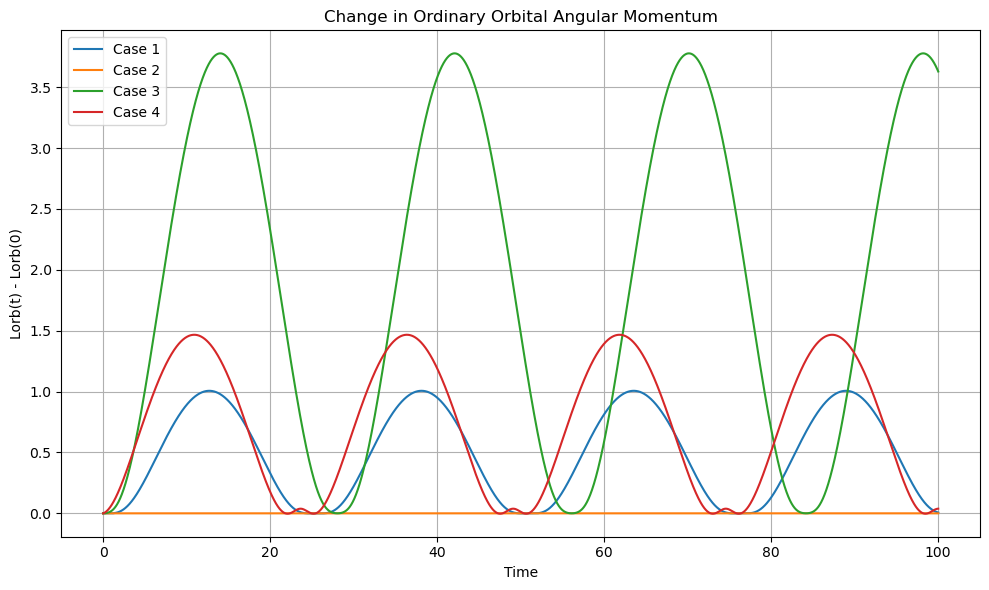


Orbital angular momentum summary:

  Case  Initial_Lorb  Minimum_Lorb  Maximum_Lorb  Max_Absolute_Change  Max_Relative_Change
Case 1      2.400000      2.399479      3.406364         1.006364e+00         4.193185e-01
Case 2      2.400000      2.400000      2.400000         1.484546e-10         6.185608e-11
Case 3      3.000000      3.000000      6.777827         3.777827e+00         1.259276e+00
Case 4      2.078461      2.075371      3.545084         1.466623e+00         7.056292e-01

Saved orbital_angular_momentum_summary.csv


In [3]:
# ============================================================
# STEP 6: ORDINARY ORBITAL ANGULAR MOMENTUM
# ============================================================

angular_momentum_results = []

plt.figure(figsize=(10, 6))

for name, solution in solutions.items():

    t = solution.t

    x = solution.y[0]
    y = solution.y[1]
    v = solution.y[2]
    theta = solution.y[3]

    # Velocity components from the nonholonomic constraint
    xdot = v * np.cos(theta)
    ydot = v * np.sin(theta)

    # Ordinary orbital angular momentum
    Lorb = M * (
        x * ydot
        -
        y * xdot
    )

    L0 = Lorb[0]

    max_abs_change = np.max(
        np.abs(
            Lorb - L0
        )
    )

    max_relative_change = (
        max_abs_change
        /
        max(abs(L0), 1e-15)
    )

    angular_momentum_results.append({
        "Case": name,
        "Initial_Lorb": L0,
        "Minimum_Lorb": np.min(Lorb),
        "Maximum_Lorb": np.max(Lorb),
        "Max_Absolute_Change": max_abs_change,
        "Max_Relative_Change": max_relative_change
    })

    print()
    print(name)
    print("Initial Lorb =", L0)
    print("Minimum Lorb =", np.min(Lorb))
    print("Maximum Lorb =", np.max(Lorb))
    print("Maximum absolute change =", max_abs_change)
    print("Maximum relative change =", max_relative_change)

    plt.plot(
        t,
        Lorb,
        label=name
    )


plt.xlabel("Time")
plt.ylabel("Orbital Angular Momentum")

plt.title(
    "Ordinary Orbital Angular Momentum"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "orbital_angular_momentum_all_cases.png",
    dpi=300
)

plt.show()


# ============================================================
# Plot change from initial value
# ============================================================

plt.figure(figsize=(10, 6))

for name, solution in solutions.items():

    t = solution.t

    x = solution.y[0]
    y = solution.y[1]
    v = solution.y[2]
    theta = solution.y[3]

    xdot = v * np.cos(theta)
    ydot = v * np.sin(theta)

    Lorb = M * (
        x * ydot
        -
        y * xdot
    )

    delta_L = (
        Lorb - Lorb[0]
    )

    plt.plot(
        t,
        delta_L,
        label=name
    )


plt.xlabel("Time")
plt.ylabel("Lorb(t) - Lorb(0)")

plt.title(
    "Change in Ordinary Orbital Angular Momentum"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "orbital_angular_momentum_change.png",
    dpi=300
)

plt.show()


# ============================================================
# Save summary table
# ============================================================

angular_momentum_summary = pd.DataFrame(
    angular_momentum_results
)

print()
print("Orbital angular momentum summary:")
print()

print(
    angular_momentum_summary.to_string(
        index=False
    )
)

angular_momentum_summary.to_csv(
    "orbital_angular_momentum_summary.csv",
    index=False
)

print()
print(
    "Saved orbital_angular_momentum_summary.csv"
)

# 6. Ordinary Orbital Angular Momentum

The ordinary orbital angular momentum of the disk center is

$$
L_{\mathrm{orb}}
=
M(x\dot y-y\dot x).
$$

Using

$$
\dot x=v\cos\theta
$$

and

$$
\dot y=v\sin\theta,
$$

this becomes

$$
L_{\mathrm{orb}}
=
Mv(x\sin\theta-y\cos\theta).
$$

The orbital angular momentum was calculated at every time step for all four initial conditions.

## Numerical Results

| Case | Initial Lorb | Minimum Lorb | Maximum Lorb | Maximum Relative Change |
| --- | ---: | ---: | ---: | ---: |
| Case 1 | 2.4000 | 2.3995 | 3.4064 | 41.9% |
| Case 2 | 2.4000 | 2.4000 | 2.4000 | approximately 0% |
| Case 3 | 3.0000 | 3.0000 | 6.7778 | 125.9% |
| Case 4 | 2.0785 | 2.0754 | 3.5451 | 70.6% |

![Orbital angular momentum](orbital_angular_momentum_all_cases.png)

The change from the initial angular momentum was also plotted.

![Change in orbital angular momentum](orbital_angular_momentum_change.png)

Cases 1, 3, and 4 show large periodic changes in orbital angular momentum. Therefore, ordinary orbital angular momentum is not conserved in general.

Case 2 is different. Its angular momentum remains equal to approximately

$$
L_{\mathrm{orb}}=2.4
$$

throughout the simulation, with a maximum numerical change of only about

$$
1.5\times10^{-10}.
$$

This is numerical error and indicates that Case 2 has constant orbital angular momentum.

## Why the Usual Kepler Argument Fails

In the ordinary Kepler problem, the only force is the central gravitational force

$$
F
=
-\frac{kq}{|q|^3}.
$$

Because this force is parallel to the position vector $q$, its torque about the Sun is zero:

$$
q\times F=0.
$$

Therefore, ordinary Kepler motion conserves orbital angular momentum.

The rolling-disk problem is different because the motion is restricted by the nonholonomic constraint

$$
\dot q=ve_\theta.
$$

The disk is not free to accelerate in any direction. Its velocity must always remain parallel to its heading.

The acceleration is

$$
\ddot q
=
\dot v e_\theta
+
v\omega e_\theta^\perp,
$$

where

$$
e_\theta^\perp
=
(-\sin\theta,\cos\theta).
$$

The second term is perpendicular to the heading and is associated with the force required to enforce the rolling constraint.

Therefore, even though gravity itself is a central force, the total effective force on the disk center includes a constraint force. That constraint force does not generally point toward the Sun and can produce a nonzero torque about the origin.

As a result,

$$
\frac{dL_{\mathrm{orb}}}{dt}
\neq 0
$$

in general.

## Direct Mathematical Check

Starting with

$$
L_{\mathrm{orb}}
=
Mv(x\sin\theta-y\cos\theta),
$$

differentiate with respect to time:

$$
\frac{dL_{\mathrm{orb}}}{dt}
=
M\dot v(x\sin\theta-y\cos\theta)
+
Mv\omega(x\cos\theta+y\sin\theta).
$$

Using

$$
M\dot v
=
-\frac{k(x\cos\theta+y\sin\theta)}
{(x^2+y^2)^{3/2}},
$$

we obtain

$$
\frac{dL_{\mathrm{orb}}}{dt}
=
(x\cos\theta+y\sin\theta)
\left[
Mv\omega
-
\frac{k(x\sin\theta-y\cos\theta)}
{(x^2+y^2)^{3/2}}
\right].
$$

This expression is not generally zero, which agrees with the numerical results.

## Why Case 2 Is Special

Case 2 follows an almost exact circular trajectory.

For Case 2,

$$
r=2,
$$

$$
v=0.8,
$$

and

$$
\omega=0.4.
$$

These satisfy

$$
\omega
=
\frac{v}{r}
=
\frac{0.8}{2}
=
0.4.
$$

The heading remains tangent to the circular path, so

$$
q\cdot e_\theta
=
x\cos\theta+y\sin\theta
=
0.
$$

Therefore,

$$
\dot v=0
$$

and

$$
\frac{dL_{\mathrm{orb}}}{dt}=0.
$$

Thus Case 2 is a special circular solution for which orbital angular momentum happens to remain constant.

## Conclusion

The numerical simulations show that ordinary orbital angular momentum is not conserved in general.

Cases 1, 3, and 4 show large changes in $L_{\mathrm{orb}}$, while Case 2 is a special circular solution for which it remains constant.

The nonholonomic rolling constraint destroys the usual Keplerian angular momentum conservation because the constraint introduces an additional force that can exert torque about the Sun even though the gravitational force itself is central.

An important result of this experiment is that energy can remain conserved while ordinary orbital angular momentum is not conserved.


Case 1
Initial Ltheta = 0.05
Minimum Ltheta = 0.05
Maximum Ltheta = 0.05
Maximum absolute change = 0.0
Maximum relative change = 0.0

Case 2
Initial Ltheta = 0.1
Minimum Ltheta = 0.1
Maximum Ltheta = 0.1
Maximum absolute change = 0.0
Maximum relative change = 0.0

Case 3
Initial Ltheta = 0.05
Minimum Ltheta = 0.05
Maximum Ltheta = 0.05
Maximum absolute change = 0.0
Maximum relative change = 0.0

Case 4
Initial Ltheta = 0.05
Minimum Ltheta = 0.05
Maximum Ltheta = 0.05
Maximum absolute change = 0.0
Maximum relative change = 0.0


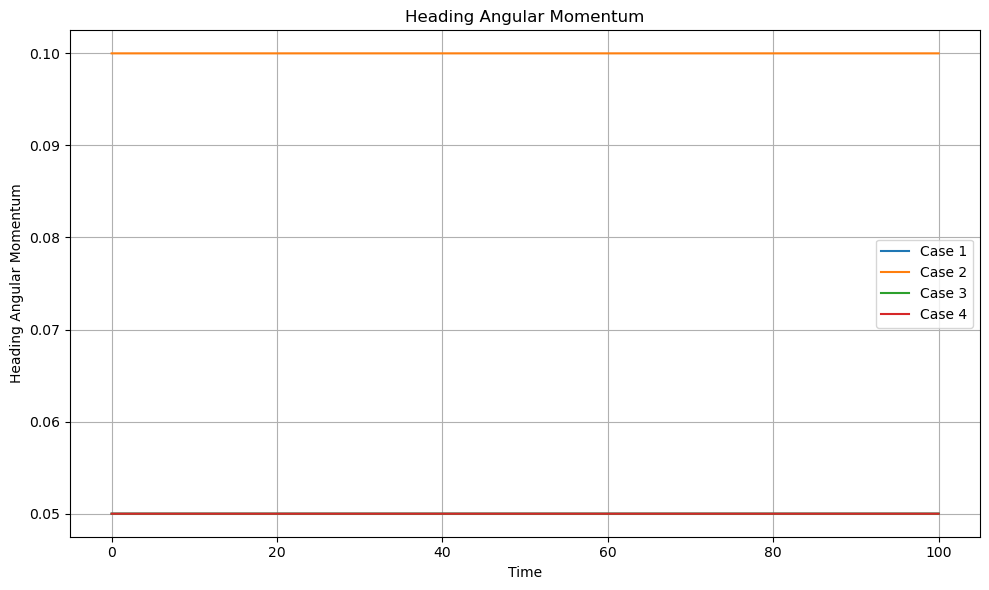

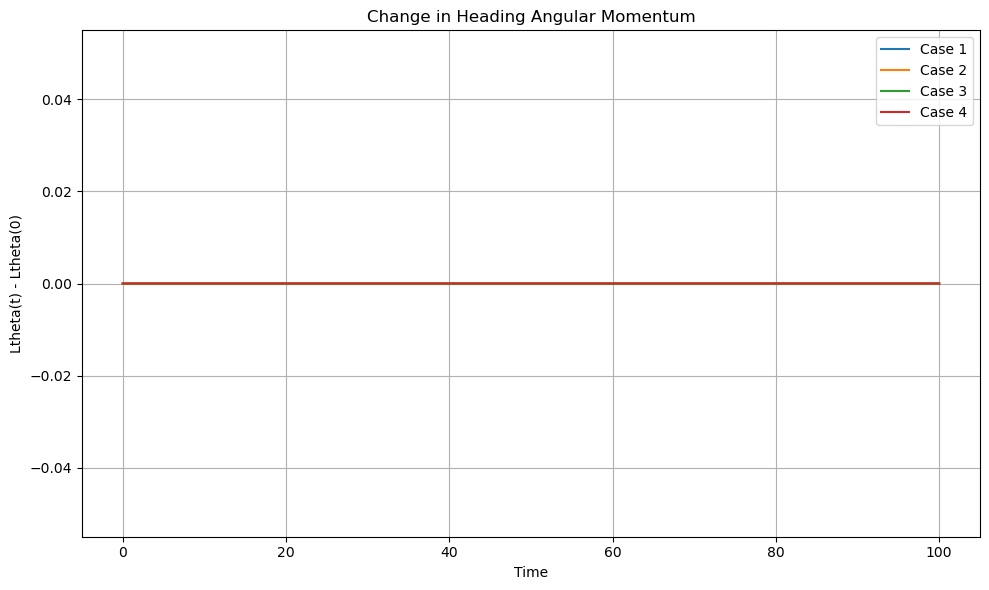


Heading angular momentum summary:

  Case  Initial_Ltheta  Minimum_Ltheta  Maximum_Ltheta  Max_Absolute_Change  Max_Relative_Change
Case 1            0.05            0.05            0.05                  0.0                  0.0
Case 2            0.10            0.10            0.10                  0.0                  0.0
Case 3            0.05            0.05            0.05                  0.0                  0.0
Case 4            0.05            0.05            0.05                  0.0                  0.0

Saved heading_angular_momentum_summary.csv


In [5]:
# ============================================================
# STEP 7: HEADING ANGULAR MOMENTUM
# ============================================================

heading_momentum_results = []

plt.figure(figsize=(10, 6))

for name, solution in solutions.items():

    t = solution.t

    omega = solution.y[4]

    # Heading angular momentum
    Ltheta = J * omega

    L0 = Ltheta[0]

    max_abs_change = np.max(
        np.abs(
            Ltheta - L0
        )
    )

    max_relative_change = (
        max_abs_change
        /
        max(abs(L0), 1e-15)
    )

    heading_momentum_results.append({
        "Case": name,
        "Initial_Ltheta": L0,
        "Minimum_Ltheta": np.min(Ltheta),
        "Maximum_Ltheta": np.max(Ltheta),
        "Max_Absolute_Change": max_abs_change,
        "Max_Relative_Change": max_relative_change
    })

    print()
    print(name)
    print("Initial Ltheta =", L0)
    print("Minimum Ltheta =", np.min(Ltheta))
    print("Maximum Ltheta =", np.max(Ltheta))
    print("Maximum absolute change =", max_abs_change)
    print("Maximum relative change =", max_relative_change)

    plt.plot(
        t,
        Ltheta,
        label=name
    )


plt.xlabel("Time")
plt.ylabel("Heading Angular Momentum")

plt.title(
    "Heading Angular Momentum"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "heading_angular_momentum_all_cases.png",
    dpi=300
)

plt.show()


# ============================================================
# Plot change from initial value
# ============================================================

plt.figure(figsize=(10, 6))

for name, solution in solutions.items():

    t = solution.t

    omega = solution.y[4]

    Ltheta = J * omega

    delta_Ltheta = (
        Ltheta - Ltheta[0]
    )

    plt.plot(
        t,
        delta_Ltheta,
        label=name
    )


plt.xlabel("Time")
plt.ylabel("Ltheta(t) - Ltheta(0)")

plt.title(
    "Change in Heading Angular Momentum"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "heading_angular_momentum_change.png",
    dpi=300
)

plt.show()


# ============================================================
# Save summary table
# ============================================================

heading_momentum_summary = pd.DataFrame(
    heading_momentum_results
)

print()
print("Heading angular momentum summary:")
print()

print(
    heading_momentum_summary.to_string(
        index=False
    )
)

heading_momentum_summary.to_csv(
    "heading_angular_momentum_summary.csv",
    index=False
)

print()
print(
    "Saved heading_angular_momentum_summary.csv"
)

# 7. Heading Angular Momentum

The heading angular momentum is defined as

$$
L_\theta = J\omega.
$$

In this simplified model, the heading equation is

$$
J\ddot{\theta}=0.
$$

Since

$$
\omega=\dot{\theta},
$$

we have

$$
\dot{\omega}=0.
$$

Therefore,

$$
\omega(t)=\omega_0
$$

for all time.

Because $J$ is also constant,

$$
L_\theta
=
J\omega
$$

must remain constant.

## Numerical Results

| Case | Initial Ltheta | Minimum Ltheta | Maximum Ltheta | Maximum Absolute Change |
| --- | ---: | ---: | ---: | ---: |
| Case 1 | 0.05 | 0.05 | 0.05 | 0.0 |
| Case 2 | 0.10 | 0.10 | 0.10 | 0.0 |
| Case 3 | 0.05 | 0.05 | 0.05 | 0.0 |
| Case 4 | 0.05 | 0.05 | 0.05 | 0.0 |

![Heading angular momentum](heading_angular_momentum_all_cases.png)

The change from the initial value is

$$
L_\theta(t)-L_\theta(0).
$$

![Change in heading angular momentum](heading_angular_momentum_change.png)

For all four cases, the change is exactly zero throughout the simulation.

## Analytical Check

Differentiate

$$
L_\theta=J\omega.
$$

Since $J$ is constant,

$$
\frac{dL_\theta}{dt}
=
J\dot{\omega}.
$$

But

$$
\dot{\omega}=0.
$$

Therefore,

$$
\frac{dL_\theta}{dt}=0.
$$

Hence,

$$
L_\theta=J\omega
$$

is conserved exactly.

## Conclusion

The heading angular momentum is conserved in this simplified model.

This agrees with both the analytical equation

$$
\dot{\omega}=0
$$

and the numerical simulations, where the heading angular momentum remained exactly constant for every initial condition.

This gives the final conservation picture:

- Energy is conserved.
- Ordinary orbital angular momentum is not conserved in general.
- Heading angular momentum is conserved.